# Chapter 9 — Factor graphs and pose graphs

Companion notebook to **Chapter 9**. The Jacobian of the SE(3) logarithm, pose-graph optimisation with loop
closures, robustness to wrong loops, and what marginalisation does to the gauge.

`vslam.posegraph.PoseGraphProblem` is just another problem for the solvers of Chapter 4: it provides `linearize` and
`retract`, and each edge is a robust block of six residuals.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent            # the code/ directory
sys.path[:0] = [str(ROOT), str(ROOT / "examples")]

import numpy as np
import matplotlib.pyplot as plt
from vslam import lie, optim, posegraph as pg, robust
from ch09_posegraph import keyframe_graph, rms, optimise, fej_spectra, SIG_T, SIG_R

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)
# after the imports: the example scripts select the Agg backend
%matplotlib inline

## 1. The right Jacobian of SE(3) and its inverse (Theorem 9.2)

$J_r(\boldsymbol\xi)=\sum_n(-\mathrm{ad}\,\boldsymbol\xi)^n/(n+1)!$ and its inverse
$\sum_nB_n(-\mathrm{ad}\,\boldsymbol\xi)^n/n!$ with the Bernoulli numbers $B_n$.

In [2]:
xi = rng.normal(size=6)
Jr = lie.se3_right_jacobian(xi)
eps = 1e-6
T_inv = lie.se3_inv(lie.se3_exp(xi))
num = np.column_stack([(lie.se3_log(T_inv @ lie.se3_exp(xi + d)) - lie.se3_log(T_inv @ lie.se3_exp(xi - d))) / (2 * eps)
                       for d in eps * np.eye(6)])
print("|J_r - finite differences|  =", np.abs(Jr - num).max())
print("|J_r^-1 J_r - I|            =", np.abs(lie.se3_right_jacobian_inv(xi) @ Jr - np.eye(6)).max())
print("rotation block = SO(3) J_r?  ", np.allclose(Jr[3:, 3:], lie.so3_right_jacobian(xi[3:])))

|J_r - finite differences|  = 4.9998893913993925e-11
|J_r^-1 J_r - I|            = 1.1102230246251565e-16
rotation block = SO(3) J_r?   True


## 2. One loop around a square (Section 9.3)

Odometry with a small heading bias drifts; a single loop-closure edge between the last and the first pose pulls the
whole trajectory back, and the correction is spread along the loop according to the odometry uncertainties.

max error: odometry 0.547 m, after optimisation 0.059 m


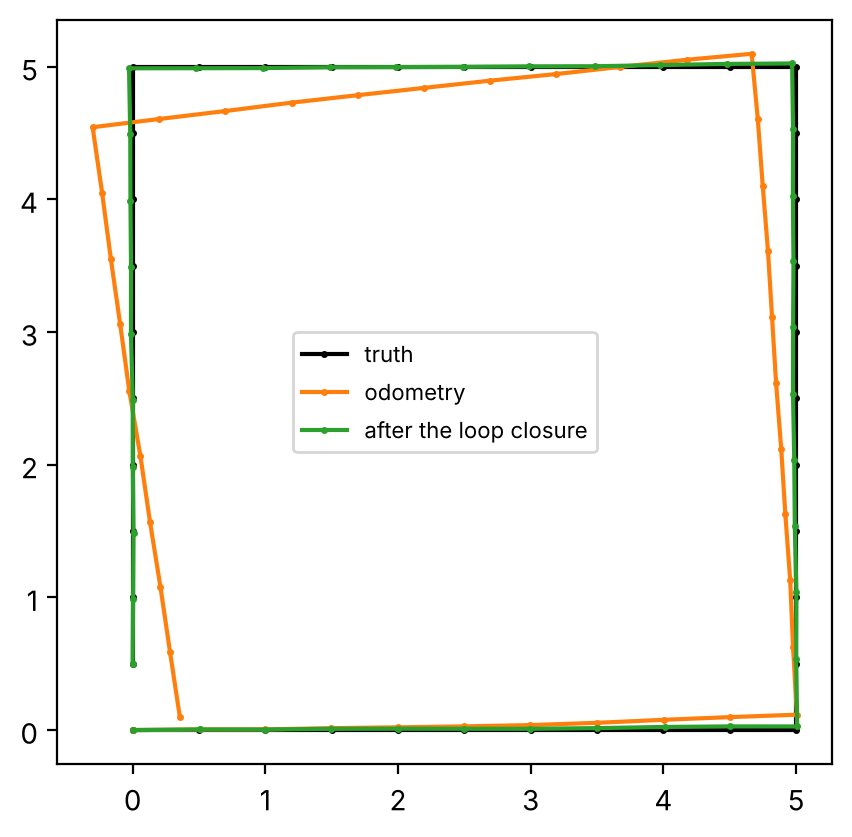

In [3]:
def square(n=10, step=0.5):
    poses, T = [], np.eye(4)
    U = lie.make_T(np.eye(3), np.array([step, 0, 0])); turn = lie.make_T(lie.so3_exp(np.array([0, 0, np.pi / 2])), np.zeros(3))
    for _ in range(4):
        for _ in range(n):
            poses.append(T.copy()); T = T @ U
        T = T @ turn
    return poses
truth = square()
est = [truth[0]]
for a, b in zip(truth[:-1], truth[1:]):
    noise = np.concatenate([rng.normal(0, 0.005, 3), rng.normal(0, 0.001, 3)]); noise[5] += 0.004
    est.append(est[-1] @ lie.se3_inv(a) @ b @ lie.se3_exp(noise))
edges = pg.odometry_edges(est, 0.005, 0.002)
edges.append(pg.Edge(0, 39, lie.se3_inv(truth[0]) @ truth[39], pg.information(0.01, 0.002), loop=True))
opt = optimise(est, edges)
fig, ax = plt.subplots(figsize=(5, 5))
for P, c, l in [(truth, "k", "truth"), (est, "tab:orange", "odometry"), (opt, "tab:green", "after the loop closure")]:
    p = np.array([T[:3, 3] for T in P]); ax.plot(p[:, 0], p[:, 1], ".-", color=c, label=l, ms=3)
ax.set_aspect("equal"); ax.legend(fontsize=8)
print(f"max error: odometry {max(np.linalg.norm(a[:3,3]-b[:3,3]) for a,b in zip(est,truth)):.3f} m, "
      f"after optimisation {max(np.linalg.norm(a[:3,3]-b[:3,3]) for a,b in zip(opt,truth)):.3f} m")

## 3. The garden: keyframes of the VO, loops between rows

Loop closures are simulated where two keyframes far apart in time see at least 30 common structure landmarks
(Chapter 10 will find them from the images). How much to trust the odometry edges matters: the per-edge errors of the
VO have a spread of about 0.6 cm and 0.06°, but they are correlated from one edge to the next.

In [4]:
world, P, G, sets = keyframe_graph()
loops = pg.covisible_loops(sets, G, np.random.default_rng(0))
print(f"{len(P)} keyframes, {len(loops)} loop closures; VO RMS error {100 * rms(P, G):.1f} cm")
for st, sr in [(0.006, 0.001), (0.02, 0.004), (0.05, 0.01)]:
    Q = optimise(P, pg.odometry_edges(P, st, sr) + loops)
    print(f"odometry sigma ({100 * st:.1f} cm, {np.degrees(sr):.2f} deg): RMS after optimisation {100 * rms(Q, G):.1f} cm")

153 keyframes, 27 loop closures; VO RMS error 36.5 cm


odometry sigma (0.6 cm, 0.06 deg): RMS after optimisation 5.6 cm


odometry sigma (2.0 cm, 0.23 deg): RMS after optimisation 3.5 cm


odometry sigma (5.0 cm, 0.57 deg): RMS after optimisation 4.3 cm


Taking the empirical per-edge spread as independent noise makes the odometry overconfident: the optimiser refuses to
bend it enough. Inflating it by three or four fixes this; a much looser value costs only a little, because the
loops then dominate. In a real system, the edge covariance comes from the BA (Proposition 8.5) and is still
optimistic for the same reason.

## 4. Wrong loops and robust kernels (Section 9.4)

In [5]:
odo = pg.odometry_edges(P, SIG_T, SIG_R)
false = []
r_ = np.random.default_rng(5)
for _ in range(5):
    i, j = sorted(r_.choice(len(P), 2, replace=False))
    false.append(pg.Edge(i, j, lie.se3_exp(np.concatenate([r_.normal(0, .3, 3), r_.normal(0, .05, 3)])), loops[0].info, loop=True))
for name, edges in [("27 correct loops", odo + loops), ("+ 5 wrong ones", odo + loops + false)]:
    print(f"{name:>18}: least squares {100 * rms(optimise(P, edges), G):7.1f} cm,"
          f"  Cauchy {100 * rms(optimise(P, edges, robust.Cauchy(1.0)), G):5.1f} cm")
over = pg.odometry_edges(P, 0.006, 0.001)
print(f"overconfident odometry + Cauchy, correct loops only: {100 * rms(optimise(P, over + loops, robust.Cauchy(1.0)), G):.1f} cm")

  27 correct loops: least squares     3.5 cm,  Cauchy   4.3 cm


    + 5 wrong ones: least squares   736.7 cm,  Cauchy   4.3 cm


overconfident odometry + Cauchy, correct loops only: 28.2 cm


The last line is the trap: with overconfident odometry, the *correct* loops have large residuals at the start
(36 cm of drift against a 2 cm loop sigma) and the Cauchy kernel discards them as outliers. Robust kernels need either
a sensible noise model or a schedule that starts permissive (graduated non-convexity).

## 5. Marginalisation and the linearisation point (Section 9.5)

An 8-node pose graph without a fixed node has a 6-dimensional gauge. Marginalise node 0: if its factors are linearised
at the same estimate as the rest, the gauge survives; if they were linearised at an older estimate — which is what
happens when a sliding window keeps a prior while the remaining nodes move — the information matrix gains spurious
information along the gauge directions.

In [6]:
full, marg = fej_spectra()
for name, ev in [("full graph", full)] + list(marg.items()):
    print(f"{name:>14}: {np.sum(ev < 1e-9 * full[-1])} zero eigenvalues; smallest six: {np.round(ev[:6] / full[-1], 12)}")

    full graph: 6 zero eigenvalues; smallest six: [-0. -0. -0.  0.  0.  0.]
    consistent: 6 zero eigenvalues; smallest six: [-0. -0. -0.  0.  0.  0.]
  inconsistent: 2 zero eigenvalues; smallest six: [-0.      0.      0.      0.      0.0001  0.0002]


## 6. Try it yourself

* In section 3, remove every other loop closure. How does the error depend on the number of loops?
* In section 4, replace the Cauchy kernel by Huber with $k=1$. Does it resist the wrong loops? Why (Chapter 4)?
* In section 5, make the older estimate closer to the newer one (smaller perturbation in `fej_spectra`). How do the
  spurious eigenvalues scale?